In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def run_bootstrap_simulation(data_files, n_samples=10000, sample_size=40):
    """
    Performs a bootstrapping simulation on NHL game data to calculate GF%.

    Args:
        data_files (list of str): A list of file paths to the CSV data files,
                                  where each file represents a single NHL season
                                  and contains a 'SEASON' column.
        n_samples (int): The number of bootstrap samples to generate for each team.
        sample_size (int): The number of games to randomly sample for each bootstrap.

    Returns:
        pandas.DataFrame: A DataFrame containing the calculated GF% for each bootstrap
                          sample, along with the corresponding team and season.
    """
    # Initialize a list to hold all the results before concatenating into a single DataFrame.
    # This is more memory-efficient than appending to a DataFrame in a loop.
    all_bootstrap_samples = []

    print(f"Starting the bootstrapping simulation for {len(data_files)} seasons...")

    # Outer loop: Iterate through each data file (season)
    for file_path in data_files:
        try:
            # Read the CSV data into a pandas DataFrame
            df = pd.read_csv(file_path)

            # Check for the required 'SEASON' column
            if 'SEASON' not in df.columns:
                print(f"Error: Skipping file {file_path}. The 'SEASON' column is missing.")
                continue

            # Get the season name directly from the DataFrame
            season = df['SEASON'].iloc[0]
            print(f"\nProcessing season: {season} from file: {file_path}")

            # Get the unique teams for the current season
            teams = df['TEAM'].unique()

            # Inner loop: Iterate through each team in the current season
            for team in teams:
                # Get all games played by the current team
                team_data = df[df['TEAM'] == team]

                # Check if the team has enough games to sample from
                if len(team_data) < sample_size:
                    print(f"  Skipping team {team} for season {season}: Not enough games ({len(team_data)}).")
                    continue

                # Innermost loop: Perform the bootstrapping simulation
                # This loop runs 'n_samples' times for each team-season
                team_bootstrap_results = []
                for i in range(n_samples):
                    # Randomly sample 'sample_size' games with replacement
                    # The 'replace=True' argument enables bootstrapping with replacement,
                    # which is the standard method for this statistical technique.
                    sampled_games = team_data.sample(n=sample_size, replace=True, random_state=i)

                    # Calculate the total Goals For and Goals Against from the sample
                    total_gf = sampled_games['GF'].sum()
                    total_ga = sampled_games['GA'].sum()

                    # Calculate the Goals For Percentage (GF%)
                    # Handle the case where total_gf + total_ga is 0 to avoid division by zero
                    if (total_gf + total_ga) == 0:
                        gf_percent = 0.0
                    else:
                        gf_percent = total_gf / (total_gf + total_ga)

                    # Store the result for this bootstrap sample
                    team_bootstrap_results.append({
                        'season': season,
                        'team': team,
                        'gf_percent': gf_percent,
                        'sample_number': i + 1
                    })

                # Convert the list of results for the current team into a DataFrame
                team_df = pd.DataFrame(team_bootstrap_results)

                # Append the team's results to the overall list
                all_bootstrap_samples.append(team_df)
                
                print(f"  Completed bootstrapping for team {team} ({n_samples} samples).")

        except FileNotFoundError:
            print(f"Error: File not found at {file_path}. Skipping.")
        except Exception as e:
            print(f"An error occurred while processing {file_path}: {e}")

    # Concatenate all the individual team DataFrames into a single, large DataFrame
    if all_bootstrap_samples:
        final_df = pd.concat(all_bootstrap_samples, ignore_index=True)
        print("\nBootstrapping simulation complete. Final DataFrame generated.")
        return final_df
    else:
        print("\nNo data processed. Returning empty DataFrame.")
        return pd.DataFrame()

In [10]:
# Bootstrapped talent distribution for all cap-era 82-game seasons

scraped_data_files = ['rawdata_talentdist_2006.csv',
                      'rawdata_talentdist_2007.csv',
                      'rawdata_talentdist_2008.csv',
                      'rawdata_talentdist_2009.csv',
                      'rawdata_talentdist_2010.csv',
                      'rawdata_talentdist_2011.csv',
                      'rawdata_talentdist_2012.csv',
                      'rawdata_talentdist_2014.csv',
                      'rawdata_talentdist_2015.csv',
                      'rawdata_talentdist_2016.csv',
                      'rawdata_talentdist_2017.csv',
                      'rawdata_talentdist_2018.csv',
                      'rawdata_talentdist_2019.csv',
                      'rawdata_talentdist_2022.csv',
                      'rawdata_talentdist_2023.csv',
                      'rawdata_talentdist_2024.csv',
                      'rawdata_talentdist_2025.csv',
                     ]

final_df_results = run_bootstrap_simulation(scraped_data_files)


Starting the bootstrapping simulation for 17 seasons...

Processing season: 2006 from file: rawdata_talentdist_2006.csv
  Completed bootstrapping for team MDA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (

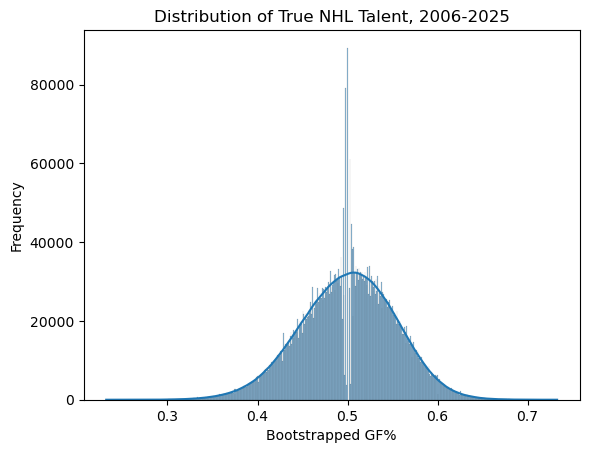

In [11]:
sns.histplot(data=final_df_results, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2006-2025")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [12]:
final_df_results['gf_percent'].mean()

np.float64(0.5001735972404701)

In [14]:
final_df_results['gf_percent'].std()

0.05283618332871113

In [15]:
# Bootstrapped talent distribution for 2005-06 through 2007-08

scraped_data_files = ['rawdata_talentdist_2006.csv',
                      'rawdata_talentdist_2007.csv',
                      'rawdata_talentdist_2008.csv',
                     ]

final_df_20062008 = run_bootstrap_simulation(scraped_data_files)


Starting the bootstrapping simulation for 3 seasons...

Processing season: 2006 from file: rawdata_talentdist_2006.csv
  Completed bootstrapping for team MDA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

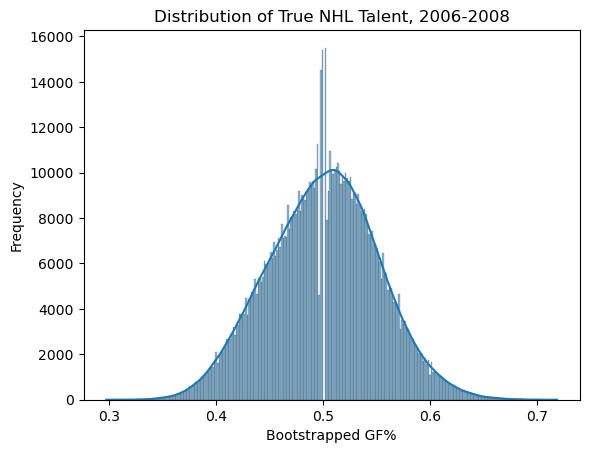

In [16]:
sns.histplot(data=final_df_20062008, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2006-2008")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [18]:
final_df_20062008['gf_percent'].mean()

np.float64(0.5003962596908975)

In [19]:
final_df_20062008['gf_percent'].std()

0.05141594506076968

In [20]:
# Bootstrapped talent distribution for 2006-07 through 2008-09

scraped_data_files = ['rawdata_talentdist_2007.csv',
                      'rawdata_talentdist_2008.csv',
                      'rawdata_talentdist_2009.csv',
                     ]

final_df_20072009 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2007 from file: rawdata_talentdist_2007.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

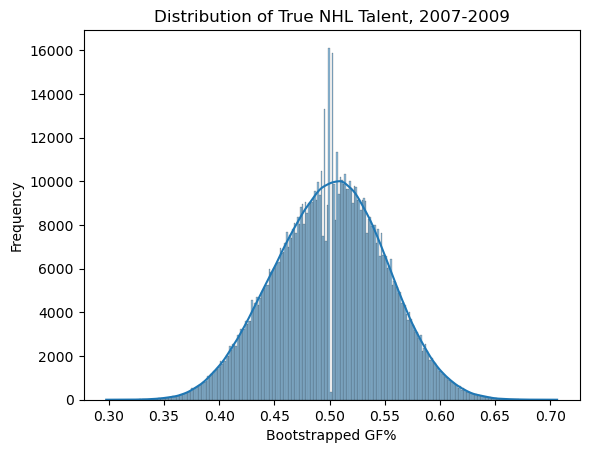

In [21]:
sns.histplot(data=final_df_20072009, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2007-2009")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [22]:
final_df_20072009['gf_percent'].mean()

np.float64(0.5003436562644719)

In [23]:
final_df_20072009['gf_percent'].std()

0.0499151180663091

In [24]:
# Bootstrapped talent distribution for 2007-08 through 2009-10

scraped_data_files = ['rawdata_talentdist_2008.csv',
                      'rawdata_talentdist_2009.csv',
                      'rawdata_talentdist_2010.csv',
                     ]

final_df_20082010 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2008 from file: rawdata_talentdist_2008.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

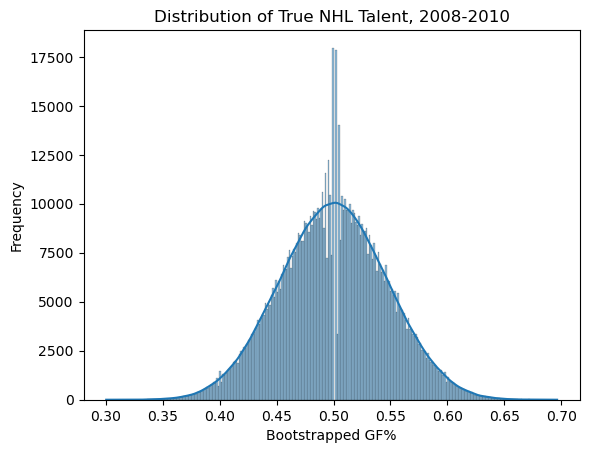

In [26]:
sns.histplot(data=final_df_20082010, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2008-2010")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [27]:
final_df_20082010['gf_percent'].mean()

np.float64(0.5001062346536005)

In [28]:
final_df_20082010['gf_percent'].std()

0.0468726079070679

In [29]:
# Bootstrapped talent distribution for 2008-09 through 2010-11

scraped_data_files = ['rawdata_talentdist_2009.csv',
                      'rawdata_talentdist_2010.csv',
                      'rawdata_talentdist_2011.csv',
                     ]

final_df_20092011 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2009 from file: rawdata_talentdist_2009.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

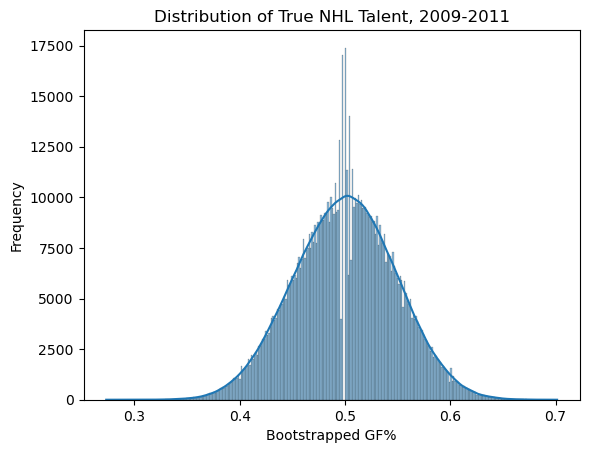

In [30]:
sns.histplot(data=final_df_20092011, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2009-2011")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [31]:
final_df_20092011['gf_percent'].mean()

np.float64(0.5000512607877949)

In [32]:
final_df_20092011['gf_percent'].std()

0.0483752039079415

In [33]:
# Bootstrapped talent distribution for 2009-10 through 2011-12

scraped_data_files = ['rawdata_talentdist_2010.csv',
                      'rawdata_talentdist_2011.csv',
                      'rawdata_talentdist_2012.csv',
                     ]

final_df_20102012 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2010 from file: rawdata_talentdist_2010.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

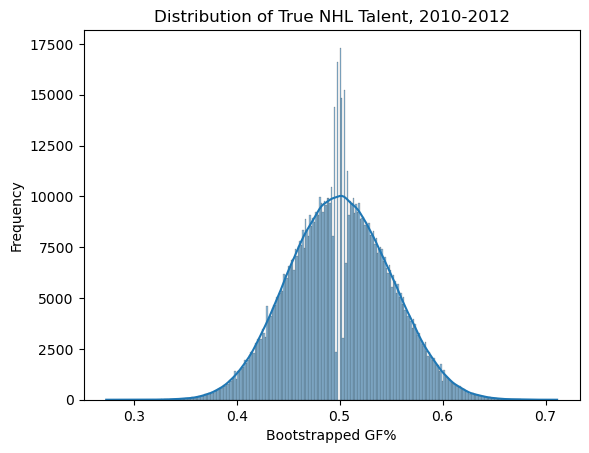

In [34]:
sns.histplot(data=final_df_20102012, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2010-2012")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [35]:
final_df_20102012['gf_percent'].mean()

np.float64(0.5001197520763055)

In [36]:
final_df_20102012['gf_percent'].std()

0.04901181391771808

In [37]:
# Bootstrapped talent distribution for 2010-11 through 2013-14, excluding partial 2012-13 season

scraped_data_files = ['rawdata_talentdist_2011.csv',
                      'rawdata_talentdist_2012.csv',
                      'rawdata_talentdist_2014.csv',
                     ]

final_df_20112014 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2011 from file: rawdata_talentdist_2011.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

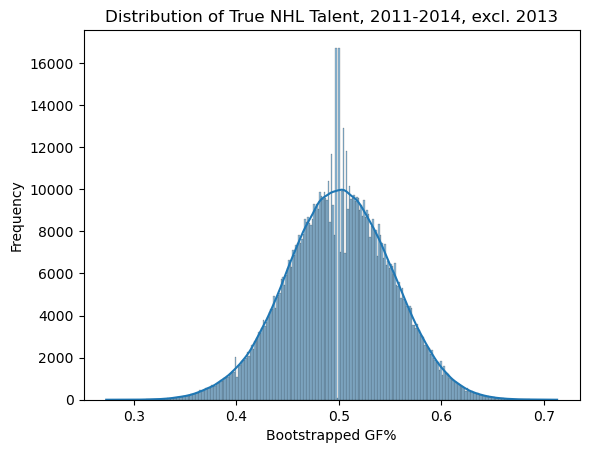

In [38]:
sns.histplot(data=final_df_20112014, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2011-2014, excl. 2013")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [39]:
final_df_20112014['gf_percent'].mean()

np.float64(0.500205577352641)

In [40]:
final_df_20112014['gf_percent'].std()

0.05144808316896817

In [41]:
# Bootstrapped talent distribution for 2011-12 through 2014-15, excluding partial 2012-13 season

scraped_data_files = ['rawdata_talentdist_2012.csv',
                      'rawdata_talentdist_2014.csv',
                      'rawdata_talentdist_2015.csv',
                     ]

final_df_20122015 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2012 from file: rawdata_talentdist_2012.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

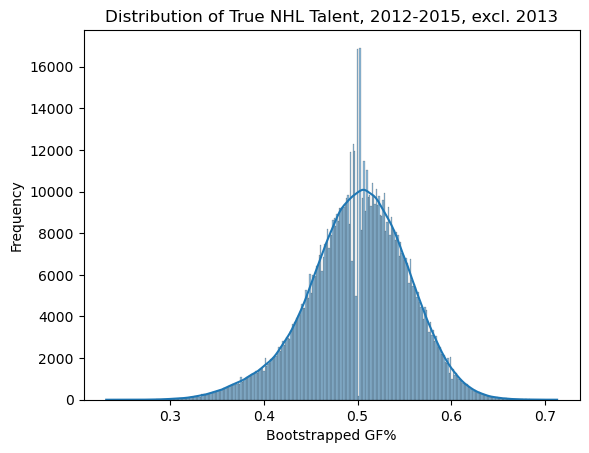

In [42]:
sns.histplot(data=final_df_20122015, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2012-2015, excl. 2013")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [43]:
final_df_20122015['gf_percent'].mean()

np.float64(0.5001222183724312)

In [44]:
final_df_20122015['gf_percent'].std()

0.05360280307681995

In [45]:
# Bootstrapped talent distribution for 2013-14 through 2015-16

scraped_data_files = ['rawdata_talentdist_2014.csv',
                      'rawdata_talentdist_2015.csv',
                      'rawdata_talentdist_2016.csv',
                     ]

final_df_20142016 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2014 from file: rawdata_talentdist_2014.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

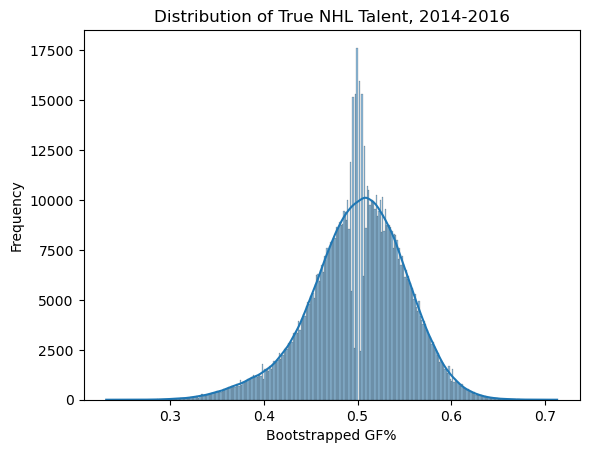

In [46]:
sns.histplot(data=final_df_20142016, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2014-2016")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [47]:
final_df_20142016['gf_percent'].mean()

np.float64(0.5000836033300471)

In [48]:
final_df_20142016['gf_percent'].std()

0.051929047599744926

In [49]:
# Bootstrapped talent distribution for 2014-15 through 2016-17

scraped_data_files = ['rawdata_talentdist_2015.csv',
                      'rawdata_talentdist_2016.csv',
                      'rawdata_talentdist_2017.csv',
                     ]

final_df_20152017 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2015 from file: rawdata_talentdist_2015.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

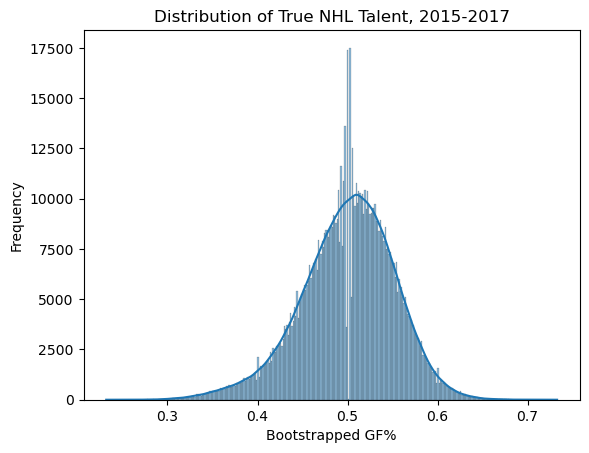

In [50]:
sns.histplot(data=final_df_20152017, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2015-2017")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [51]:
final_df_20152017['gf_percent'].mean()

np.float64(0.49989169722062626)

In [52]:
final_df_20152017['gf_percent'].std()

0.052121574215943337

In [53]:
# Bootstrapped talent distribution for 2015-16 through 2017-18

scraped_data_files = ['rawdata_talentdist_2016.csv',
                      'rawdata_talentdist_2017.csv',
                      'rawdata_talentdist_2018.csv',
                     ]

final_df_20162018 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2016 from file: rawdata_talentdist_2016.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

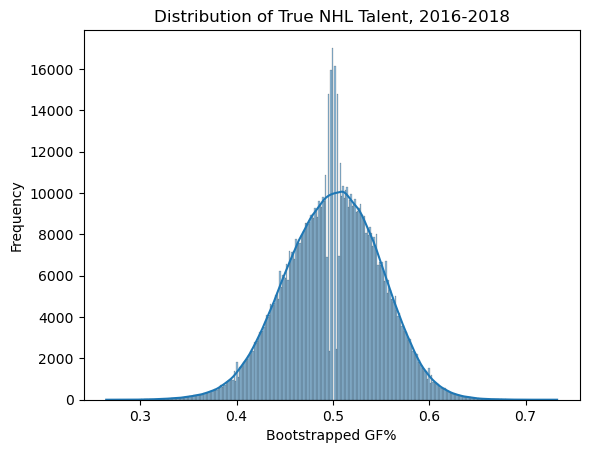

In [54]:
sns.histplot(data=final_df_20162018, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2016-2018")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [55]:
final_df_20162018['gf_percent'].mean()

np.float64(0.49988950971988577)

In [56]:
final_df_20162018['gf_percent'].std()

0.049218904401307675

In [57]:
# Bootstrapped talent distribution for 2016-17 through 2018-19

scraped_data_files = ['rawdata_talentdist_2017.csv',
                      'rawdata_talentdist_2018.csv',
                      'rawdata_talentdist_2019.csv',
                     ]

final_df_20172019 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2017 from file: rawdata_talentdist_2017.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

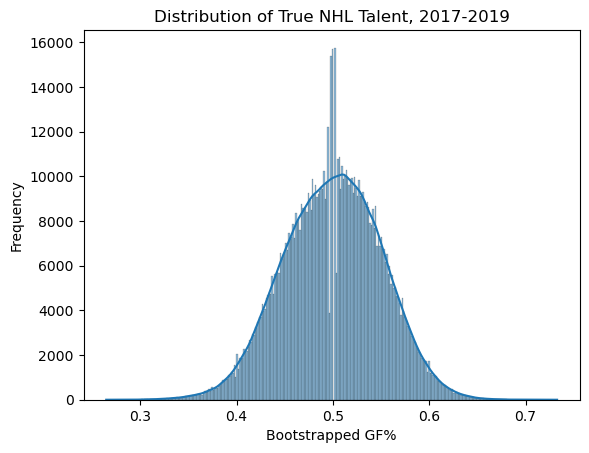

In [58]:
sns.histplot(data=final_df_20172019, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2017-2019")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [59]:
final_df_20172019['gf_percent'].mean()

np.float64(0.49972960988639387)

In [60]:
final_df_20172019['gf_percent'].std()

0.05068058700816995

In [61]:
# Bootstrapped talent distribution for 2017-18 through 2021-22, excl COVID-shortened seasons 2019-2021

scraped_data_files = ['rawdata_talentdist_2018.csv',
                      'rawdata_talentdist_2019.csv',
                      'rawdata_talentdist_2022.csv',
                     ]

final_df_20182022 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2018 from file: rawdata_talentdist_2018.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

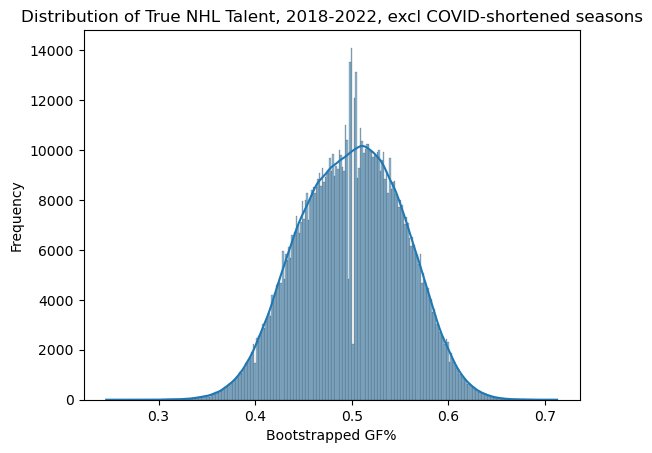

In [62]:
sns.histplot(data=final_df_20182022, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2018-2022, excl COVID-shortened seasons")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [63]:
final_df_20182022['gf_percent'].mean()

np.float64(0.4997684612816709)

In [64]:
final_df_20182022['gf_percent'].std()

0.05349971601887406

In [65]:
# Bootstrapped talent distribution for 2018-19 through 2022-23, excl COVID-shortened seasons 2019-2021

scraped_data_files = ['rawdata_talentdist_2019.csv',
                      'rawdata_talentdist_2022.csv',
                      'rawdata_talentdist_2023.csv',
                     ]

final_df_20192023 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2019 from file: rawdata_talentdist_2019.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

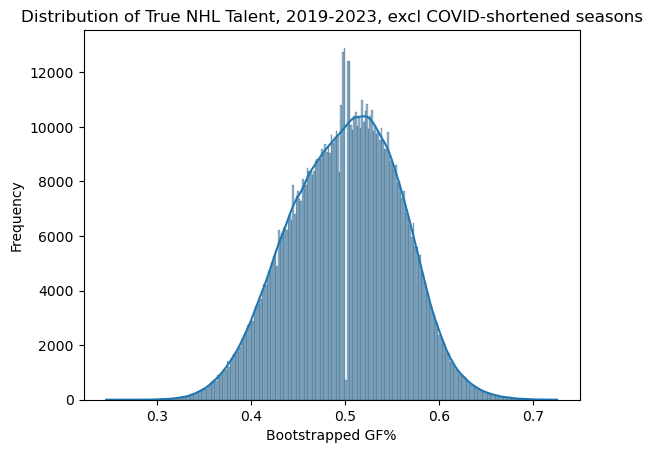

In [66]:
sns.histplot(data=final_df_20192023, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2019-2023, excl COVID-shortened seasons")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [67]:
final_df_20192023['gf_percent'].mean()

np.float64(0.5002424977770984)

In [68]:
final_df_20192023['gf_percent'].std()

0.05850114903278479

In [69]:
# Bootstrapped talent distribution for 2021-22 through 2023-24

scraped_data_files = ['rawdata_talentdist_2022.csv',
                      'rawdata_talentdist_2023.csv',
                      'rawdata_talentdist_2024.csv',
                     ]

final_df_20222024 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2022 from file: rawdata_talentdist_2022.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

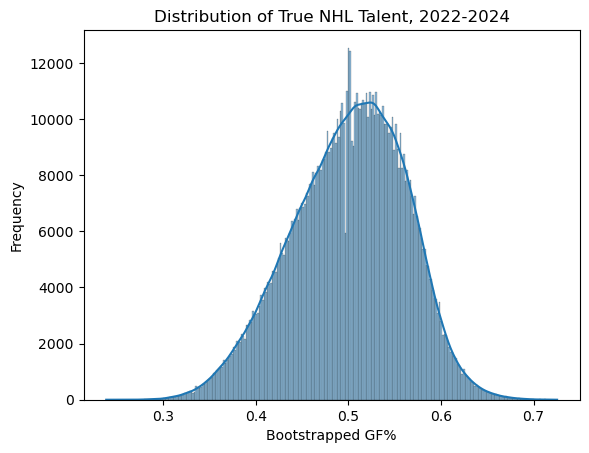

In [70]:
sns.histplot(data=final_df_20222024, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2022-2024")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [71]:
final_df_20222024['gf_percent'].mean()

np.float64(0.5004043596739318)

In [72]:
final_df_20222024['gf_percent'].std()

0.06147189570978927

In [73]:
# Bootstrapped talent distribution for 2022-23 through 2024-25

scraped_data_files = ['rawdata_talentdist_2023.csv',
                      'rawdata_talentdist_2024.csv',
                      'rawdata_talentdist_2025.csv',
                     ]

final_df_20232025 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 3 seasons...

Processing season: 2023 from file: rawdata_talentdist_2023.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

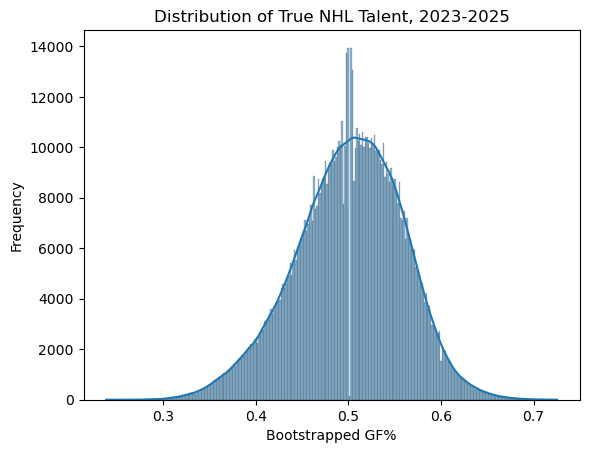

In [74]:
sns.histplot(data=final_df_20232025, x="gf_percent", kde=True)
plt.title("Distribution of True NHL Talent, 2023-2025")
plt.xlabel("Bootstrapped GF%")
plt.ylabel("Frequency")
plt.show()

In [75]:
final_df_20232025['gf_percent'].mean()

np.float64(0.5007132313233599)

0.05837960512505256

In [3]:
# Estimating the true talent distribution for the 4 32-team NHL seasons

scraped_data_files = ['rawdata_talentdist_2022.csv',
                      'rawdata_talentdist_2023.csv',
                      'rawdata_talentdist_2024.csv',
                      'rawdata_talentdist_2025.csv'
                     ]

final_df_20222025 = run_bootstrap_simulation(scraped_data_files)

Starting the bootstrapping simulation for 4 seasons...

Processing season: 2022 from file: rawdata_talentdist_2022.csv
  Completed bootstrapping for team ANA (10000 samples).
  Completed bootstrapping for team BOS (10000 samples).
  Completed bootstrapping for team BUF (10000 samples).
  Completed bootstrapping for team CAR (10000 samples).
  Completed bootstrapping for team CBJ (10000 samples).
  Completed bootstrapping for team CHI (10000 samples).
  Completed bootstrapping for team CGY (10000 samples).
  Completed bootstrapping for team COL (10000 samples).
  Completed bootstrapping for team DAL (10000 samples).
  Completed bootstrapping for team DET (10000 samples).
  Completed bootstrapping for team EDM (10000 samples).
  Completed bootstrapping for team FLA (10000 samples).
  Completed bootstrapping for team LAK (10000 samples).
  Completed bootstrapping for team MIN (10000 samples).
  Completed bootstrapping for team MTL (10000 samples).
  Completed bootstrapping for team NJD (1

In [4]:
final_df_20222025['gf_percent'].std()

0.05926608783171769